In [66]:
import numpy as np
import sys
import itertools
import matplotlib.pyplot as plt
sys.path.append("..")
from model.hopfield_network import HopfieldNetwork, SequentialHopfieldNetwork, SequentialHopfieldNetwork2

In [67]:
# load pict.dat file (format -1,1..) and plot the patterns
pict_data = np.loadtxt('../pict.dat', delimiter=',')
print(f"\nLoaded pict.dat with shape: {pict_data.shape}")
pict_data = pict_data.reshape(-1, 1024)

print(f"\nLoaded pict.dat with shape: {pict_data.shape}")

# Plot the patterns 32x32
num_patterns = pict_data.shape[0]
print(f"Number of patterns in pict.dat: {num_patterns}")


Loaded pict.dat with shape: (11264,)

Loaded pict.dat with shape: (11, 1024)
Number of patterns in pict.dat: 11


In [68]:
p1 = pict_data[0]
p2 = pict_data[1]
p3 = pict_data[2]
p4 = pict_data[3]
p5 = pict_data[4]
p6 = pict_data[5]
p7 = pict_data[6]
p8 = pict_data[7]
p9 = pict_data[8]

p10 = pict_data[9]
p11 = pict_data[10]

training_patterns = np.array([p1, p2, p3])

In [69]:
def plot_state(state):
    # Plot the recalled pattern
    plt.imshow(state.reshape(32, 32), cmap='gray')
    plt.title('Recalled Pattern')
    plt.axis('off')
    plt.show()

In [70]:
network = HopfieldNetwork(training_patterns)

print("Network created")
print(f"Number of neurons: {network.n_neurons}")
print(f"Weight matrix shape: {network.W.shape}")



Network created
Number of neurons: 1024
Weight matrix shape: (1024, 1024)


In [71]:
def add_noise(pattern, noise_level):
    """
    Add noise to a pattern by flipping a percentage of its bits.
    
    :param pattern: The original pattern (1D numpy array).
    :param noise_level: The percentage of bits to flip (0 to 1).
    :return: The noisy pattern.
    """
    noisy_pattern = pattern.copy()
    num_flips = int(noise_level * len(pattern))
    flip_indices = np.random.choice(len(pattern), size=num_flips, replace=False)
    noisy_pattern[flip_indices] *= -1  # Flip the bits
    return noisy_pattern

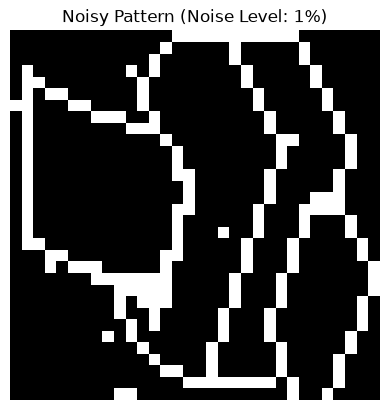

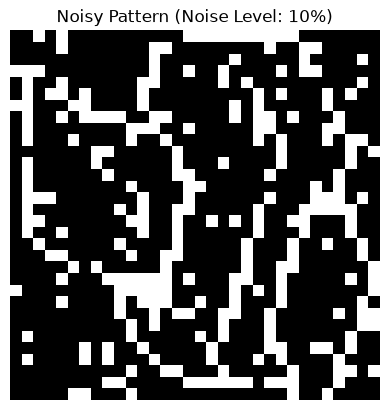

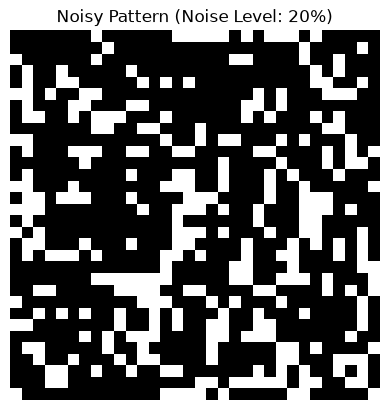

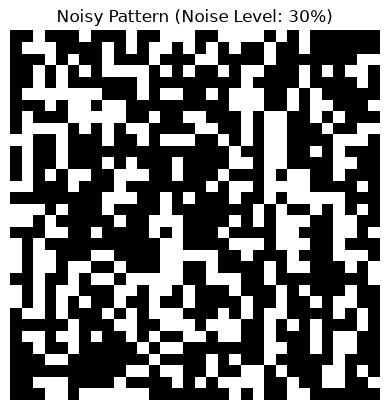

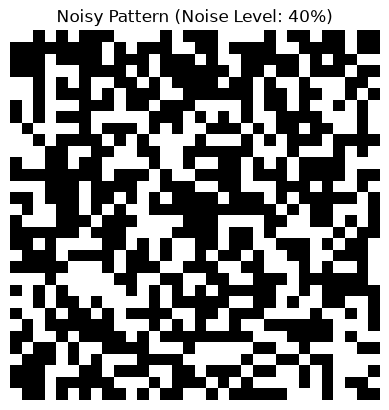

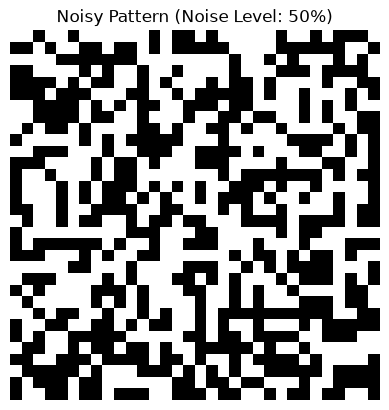

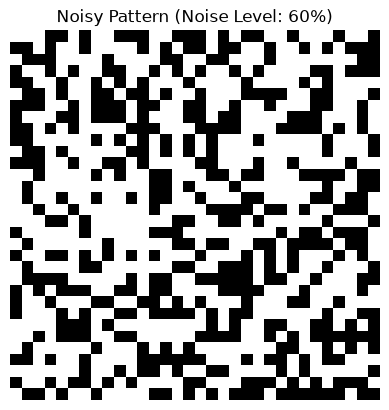

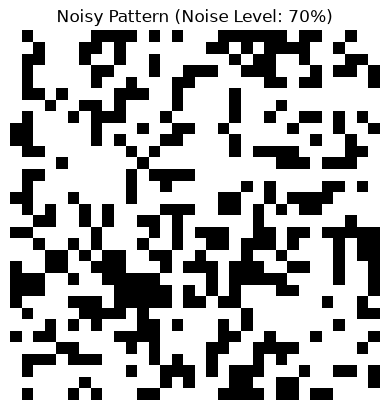

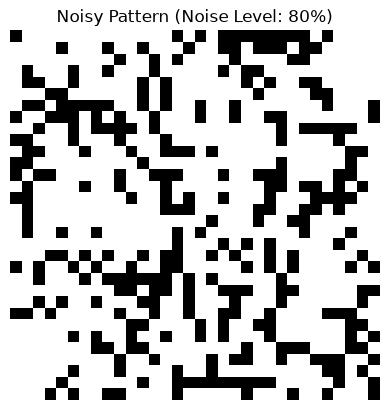

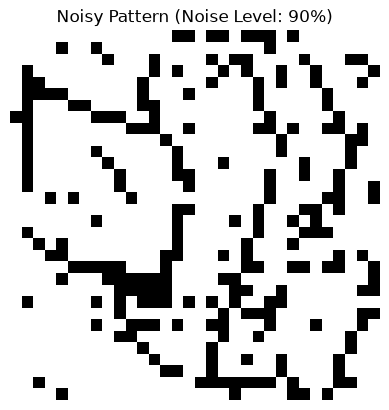

In [72]:
noisy_patterns = []
for noise_level in np.linspace(0.01, 0.9, 10):
    noisy_pattern = add_noise(p1, noise_level)
    noisy_patterns.append(noisy_pattern)

    plt.imshow(noisy_pattern.reshape(32, 32), cmap='gray')
    plt.title(f'Noisy Pattern (Noise Level: {int(noise_level * 100)}%)')
    plt.axis('off')
    plt.show()

Noise Level: 1%


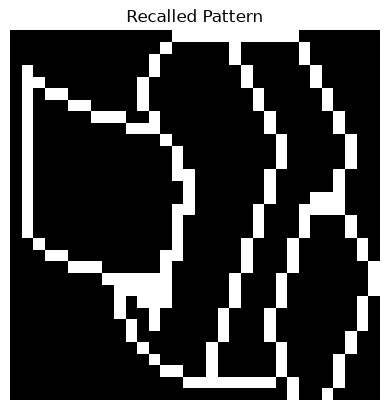

Noise Level: 10%


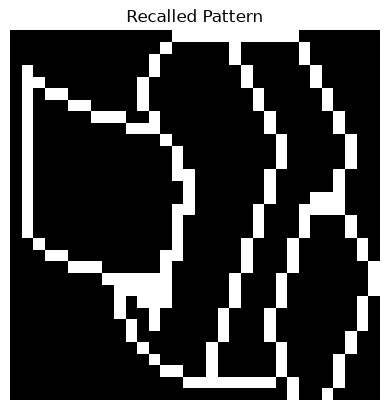

Noise Level: 20%


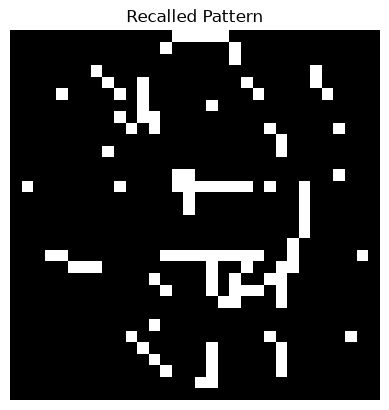

Noise Level: 30%


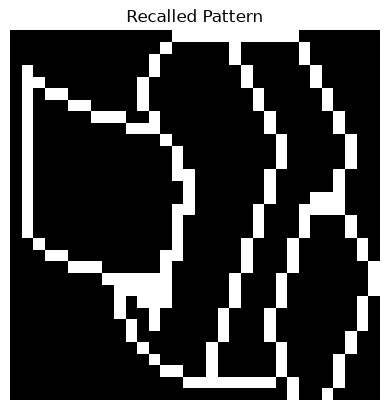

Noise Level: 40%


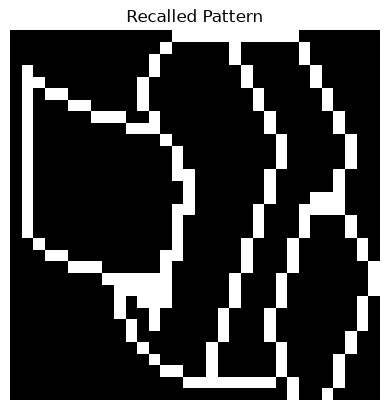

Noise Level: 50%


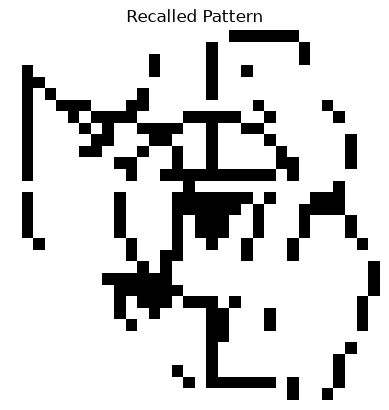

Noise Level: 60%


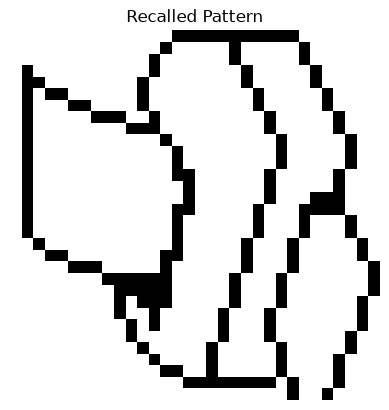

Noise Level: 70%


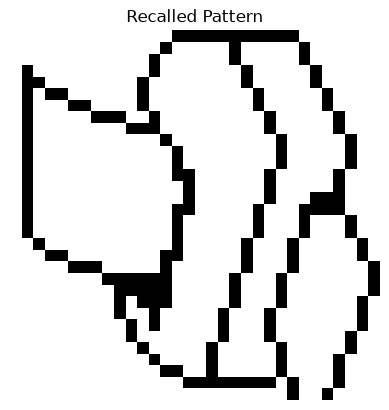

Noise Level: 80%


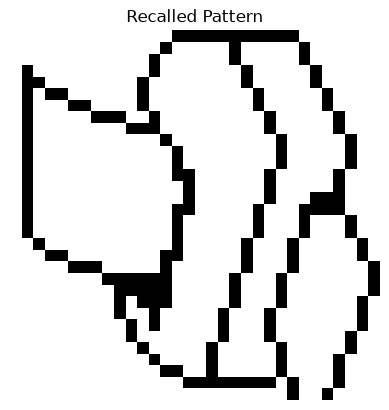

Noise Level: 90%


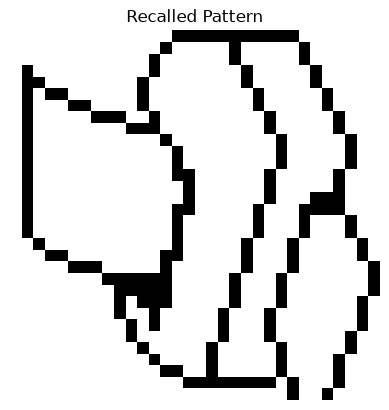

In [73]:
for i, noisy_pattern in enumerate(noisy_patterns):
    recalled, history, stable = network.recall(
        noisy_pattern,
        max_iterations=1,
    )

    print(f"Noise Level: {int(np.linspace(0.01, 0.9, 10)[i] * 100)}%")
    plot_state(recalled)

Number of patterns: 3, Noise Level: 1%


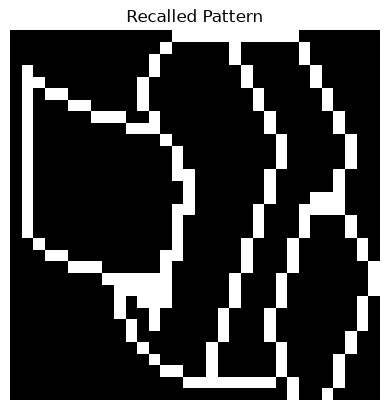

Number of patterns: 3, Noise Level: 10%


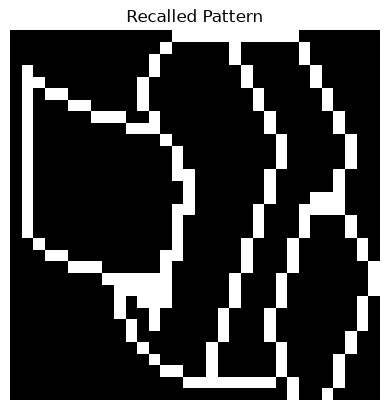

Number of patterns: 3, Noise Level: 20%


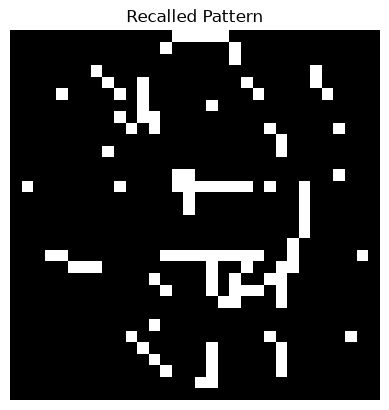

Number of patterns: 3, Noise Level: 30%


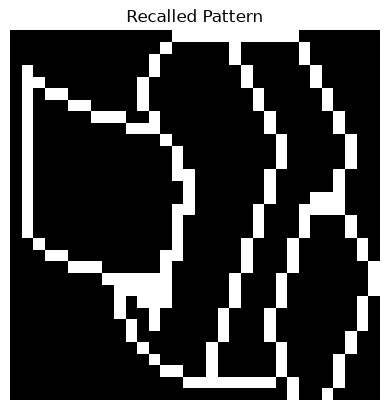

Number of patterns: 3, Noise Level: 40%


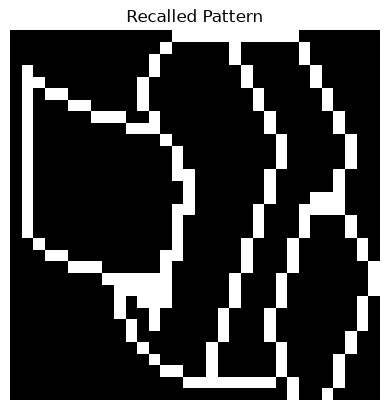

Number of patterns: 3, Noise Level: 50%


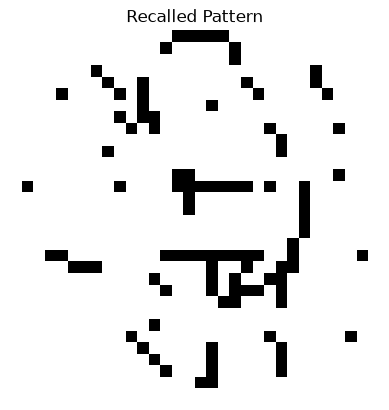

Number of patterns: 3, Noise Level: 60%


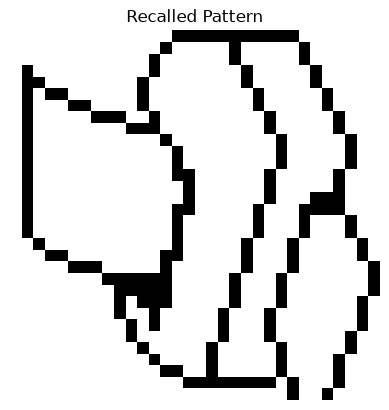

Number of patterns: 3, Noise Level: 70%


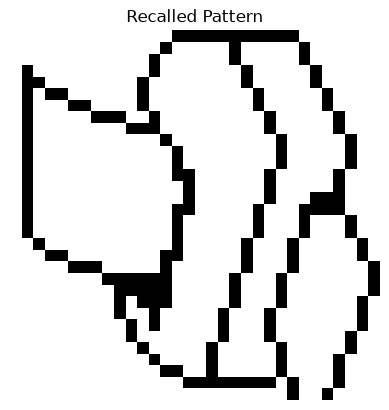

Number of patterns: 3, Noise Level: 80%


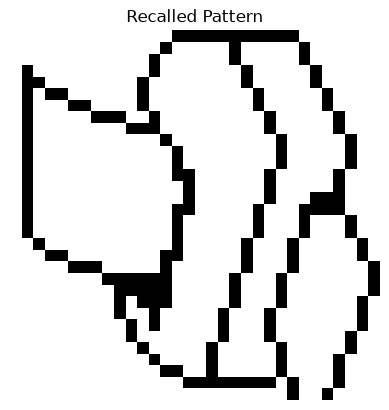

Number of patterns: 3, Noise Level: 90%


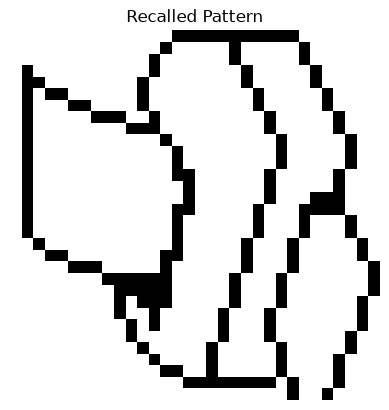

Number of patterns: 4, Noise Level: 1%


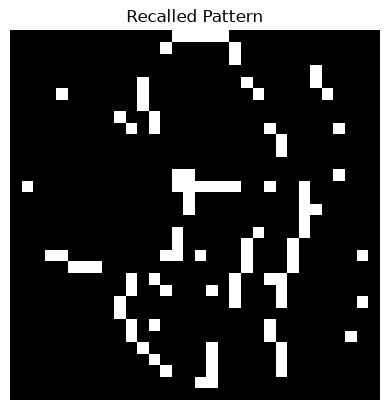

Number of patterns: 4, Noise Level: 10%


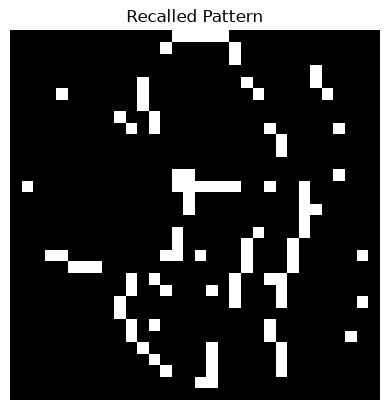

Number of patterns: 4, Noise Level: 20%


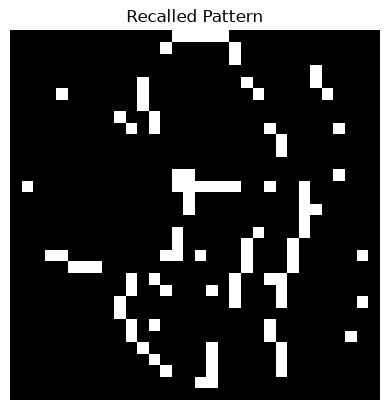

Number of patterns: 4, Noise Level: 30%


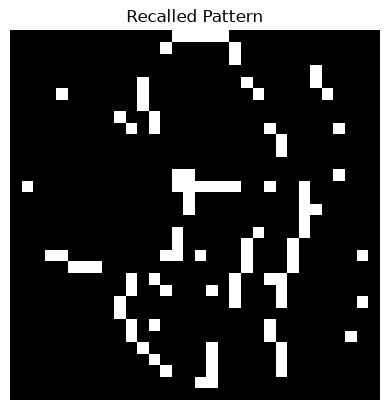

Number of patterns: 4, Noise Level: 40%


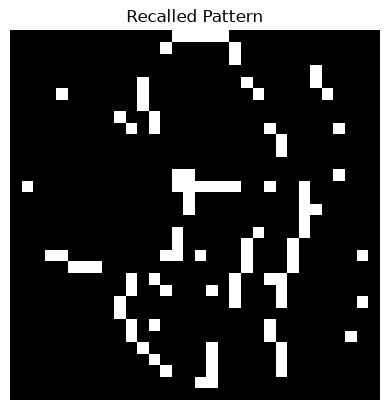

Number of patterns: 4, Noise Level: 50%


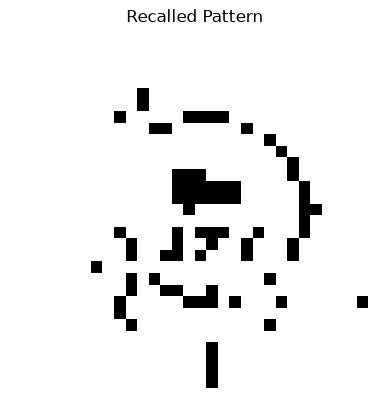

Number of patterns: 4, Noise Level: 60%


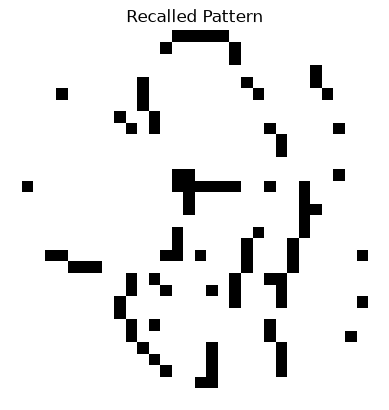

Number of patterns: 4, Noise Level: 70%


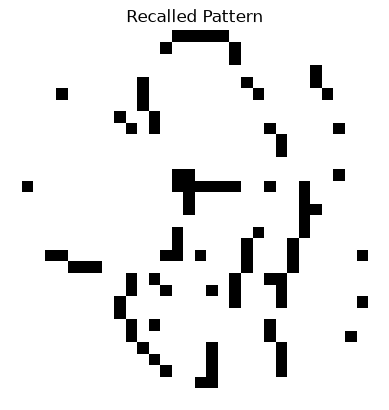

Number of patterns: 4, Noise Level: 80%


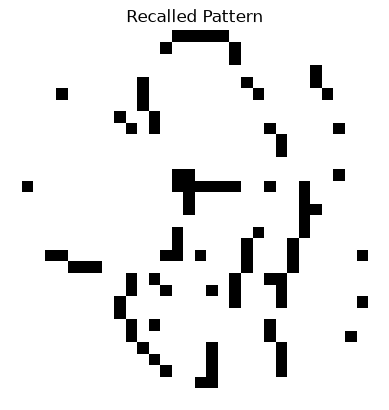

Number of patterns: 4, Noise Level: 90%


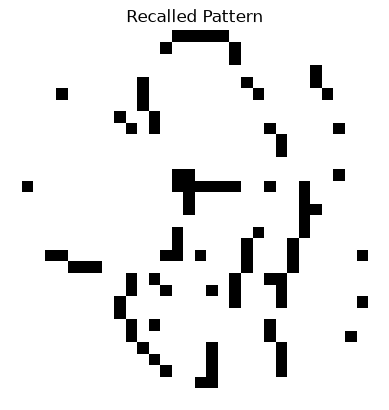

Number of patterns: 5, Noise Level: 1%


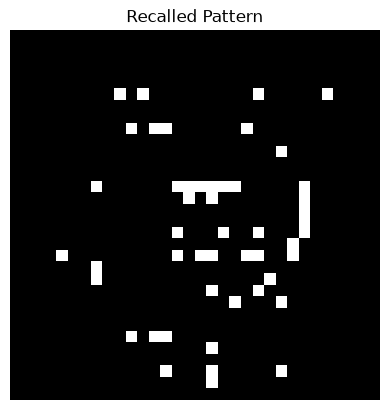

Number of patterns: 5, Noise Level: 10%


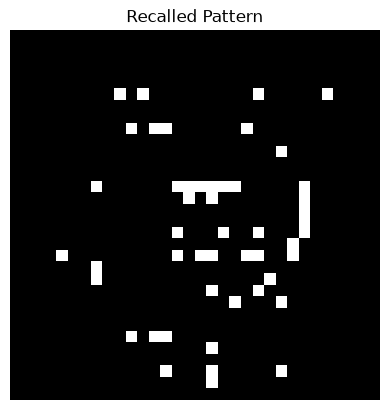

Number of patterns: 5, Noise Level: 20%


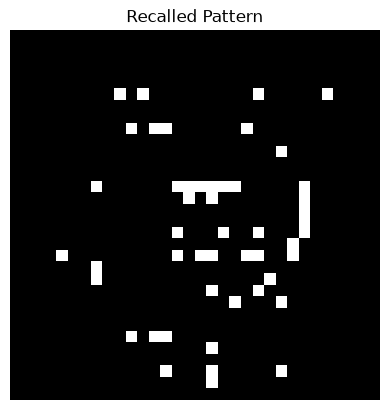

Number of patterns: 5, Noise Level: 30%


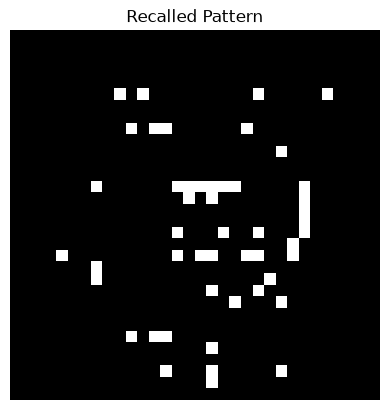

Number of patterns: 5, Noise Level: 40%


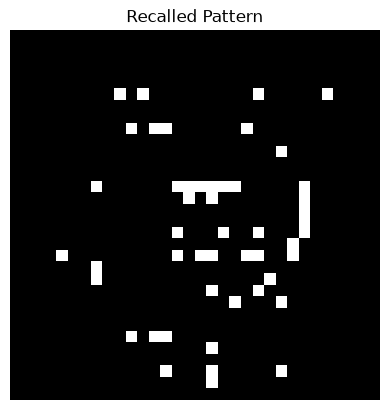

Number of patterns: 5, Noise Level: 50%


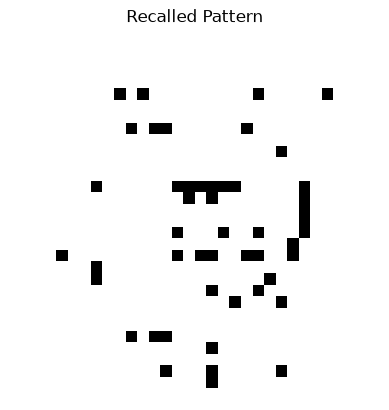

Number of patterns: 5, Noise Level: 60%


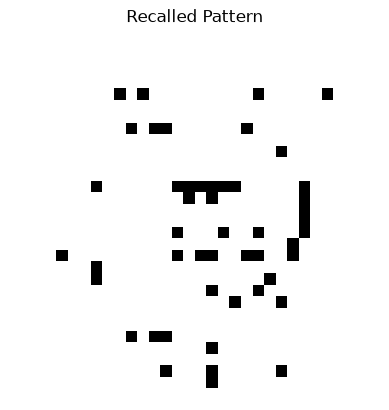

Number of patterns: 5, Noise Level: 70%


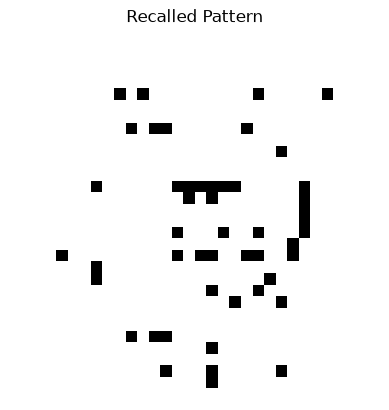

Number of patterns: 5, Noise Level: 80%


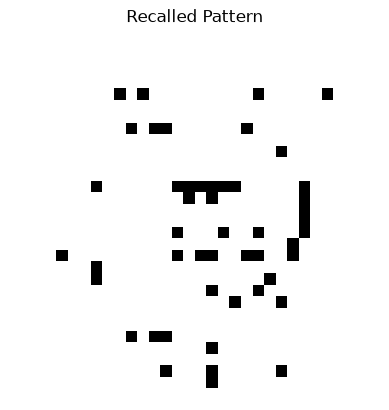

Number of patterns: 5, Noise Level: 90%


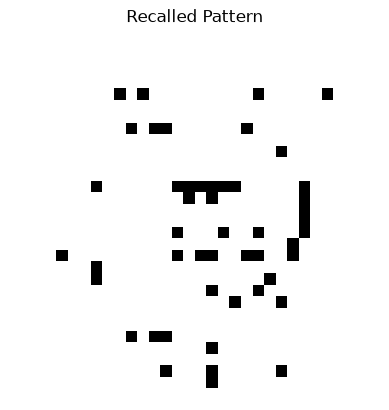

Number of patterns: 6, Noise Level: 1%


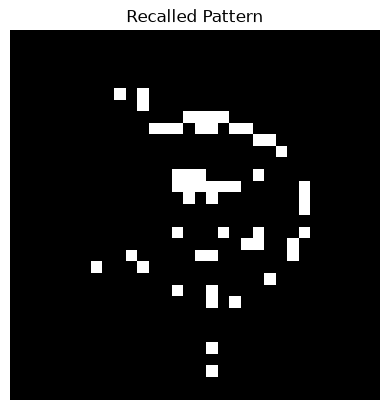

Number of patterns: 6, Noise Level: 10%


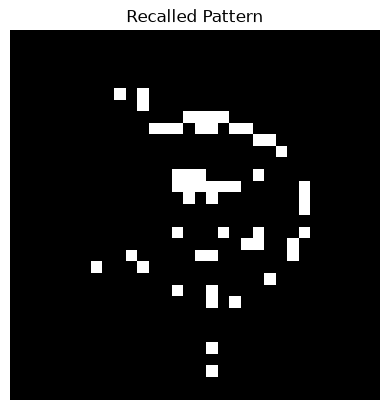

Number of patterns: 6, Noise Level: 20%


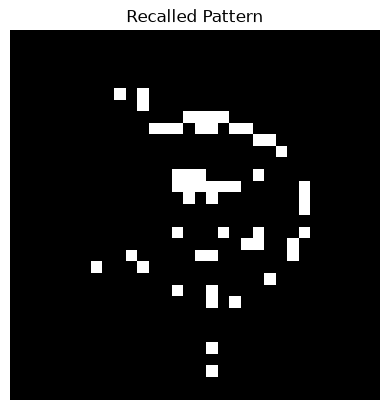

Number of patterns: 6, Noise Level: 30%


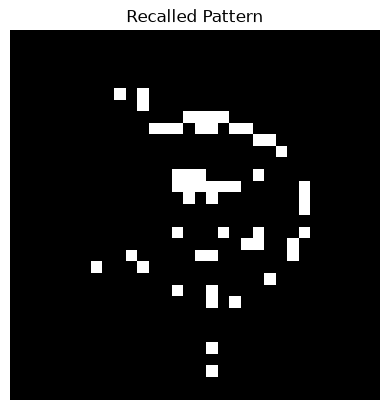

Number of patterns: 6, Noise Level: 40%


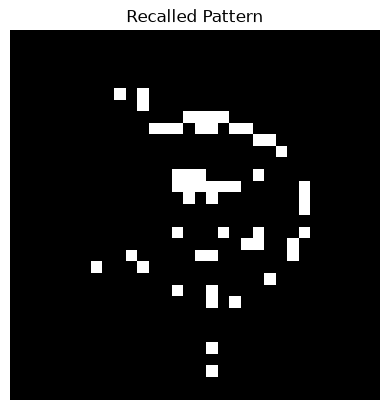

Number of patterns: 6, Noise Level: 50%


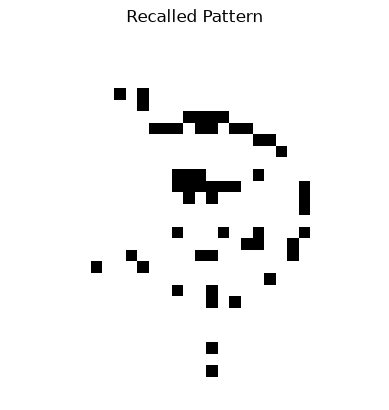

Number of patterns: 6, Noise Level: 60%


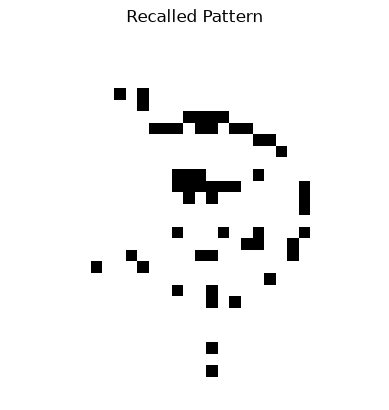

Number of patterns: 6, Noise Level: 70%


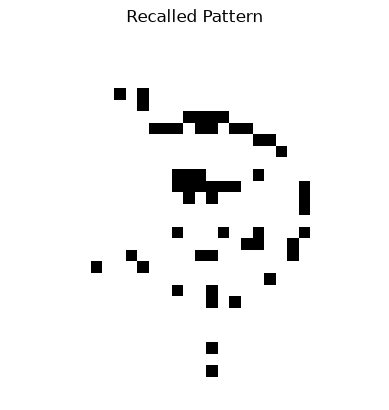

Number of patterns: 6, Noise Level: 80%


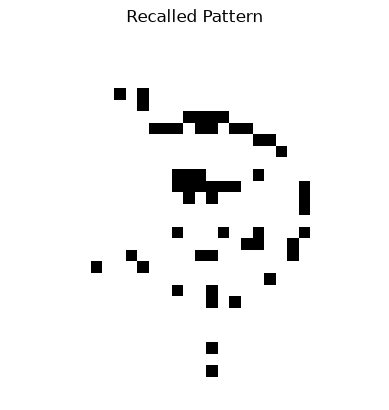

Number of patterns: 6, Noise Level: 90%


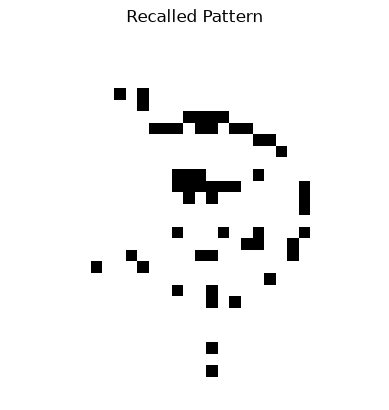

Number of patterns: 7, Noise Level: 1%


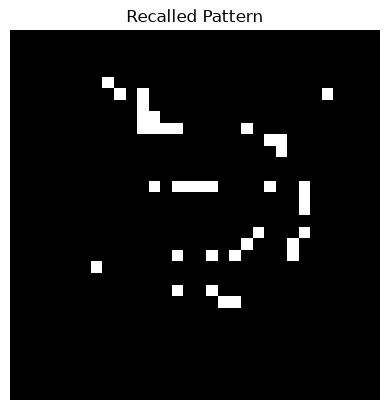

Number of patterns: 7, Noise Level: 10%


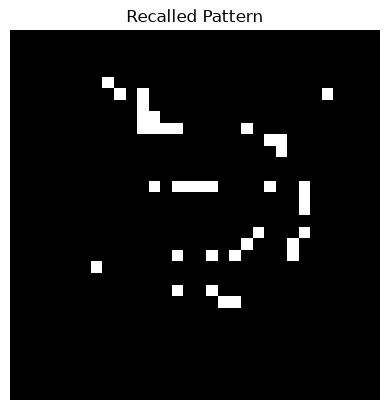

Number of patterns: 7, Noise Level: 20%


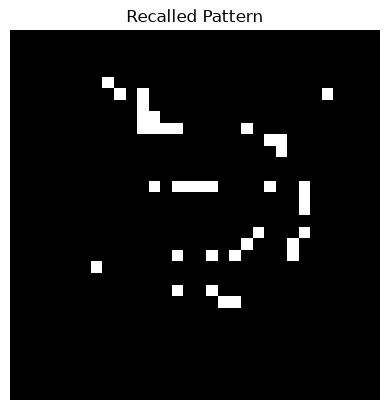

Number of patterns: 7, Noise Level: 30%


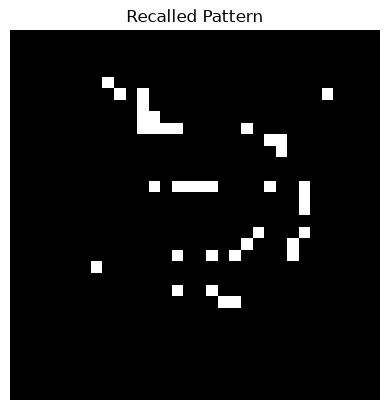

Number of patterns: 7, Noise Level: 40%


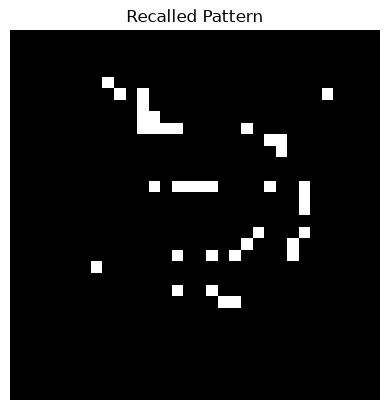

Number of patterns: 7, Noise Level: 50%


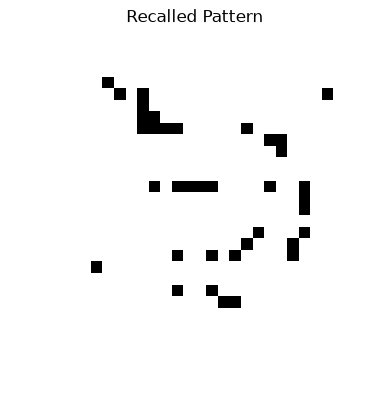

Number of patterns: 7, Noise Level: 60%


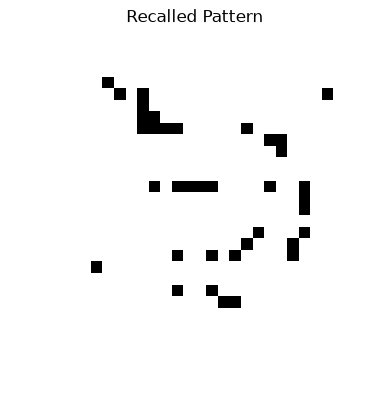

Number of patterns: 7, Noise Level: 70%


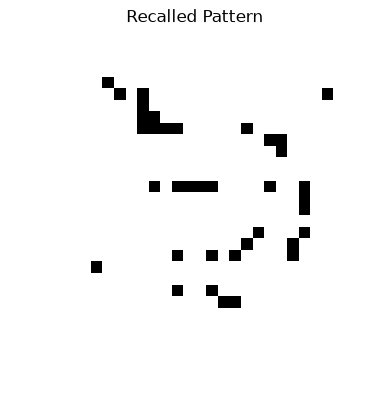

Number of patterns: 7, Noise Level: 80%


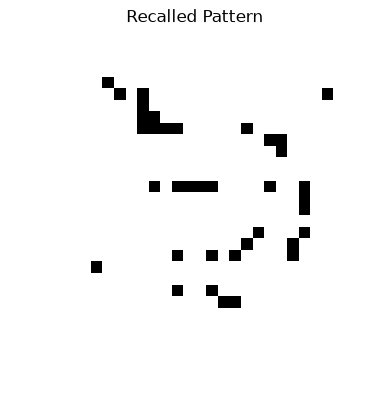

Number of patterns: 7, Noise Level: 90%


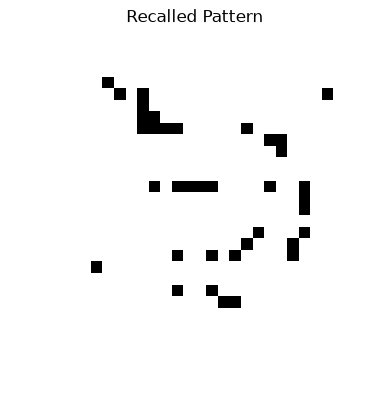

In [76]:
for i in range(3,len(pict_data)-3):
    patterns = pict_data[:i]
    network = HopfieldNetwork(patterns)
    
    for j in range(len(noisy_patterns)):
        recalled, history, stable = network.recall(
            noisy_patterns[j],
            max_iterations=5000,
        )
        print(f"Number of patterns: {i}, Noise Level: {int(np.linspace(0.01, 0.9, 10)[j] * 100)}%")
        plot_state(recalled)

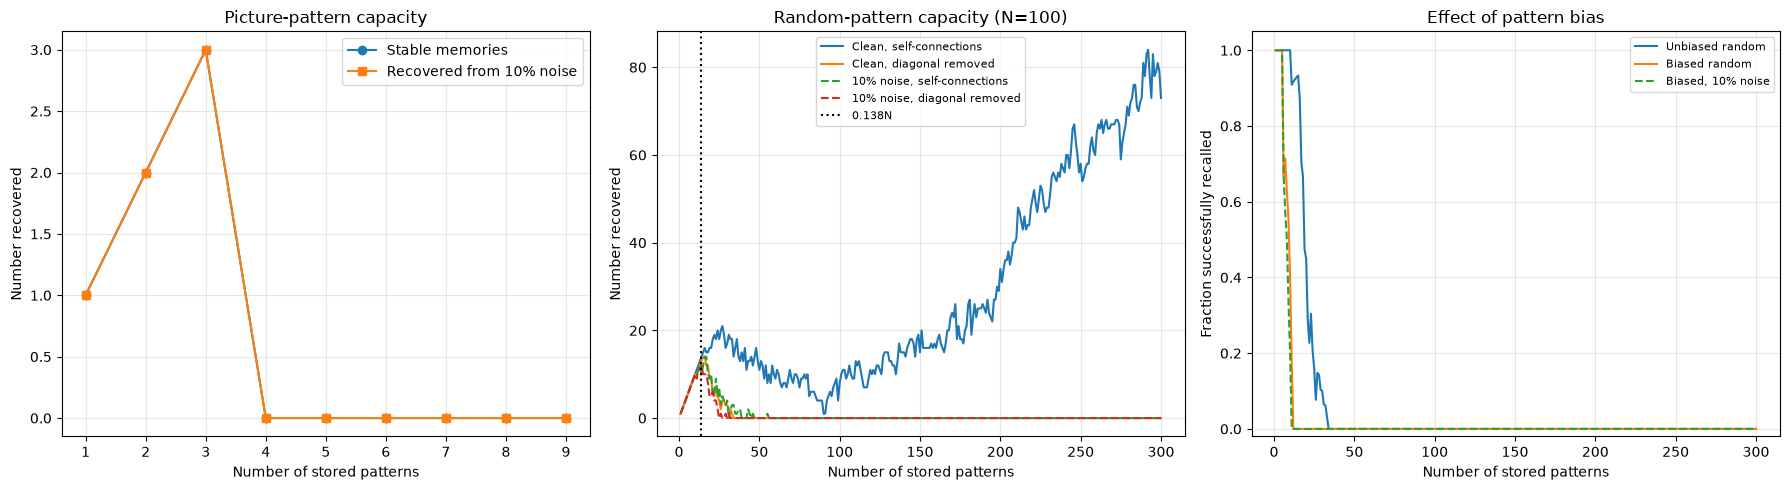

Picture memories stable at maximum load: 0/9
Random clean capacity with self-connections: 16
Random clean capacity without self-connections: 10
Biased random memories stable at maximum load: 0/300


In [77]:
# Section 3.5: capacity experiments
# The fixed seed makes the random-pattern comparisons reproducible.
rng = np.random.default_rng(3)


def build_network(patterns, remove_self_connections=False):
    network = HopfieldNetwork(np.asarray(patterns))
    if remove_self_connections:
        np.fill_diagonal(network.W, 0)
    return network


def flip_bits(pattern, fraction, generator):
    noisy = np.asarray(pattern).copy()
    n_flips = int(round(fraction * noisy.size))
    if n_flips:
        indices = generator.choice(noisy.size, size=n_flips, replace=False)
        noisy[indices] *= -1
    return noisy


def stable_count(network, patterns):
    return sum(network.is_stable(pattern) for pattern in patterns)


def noisy_recall_rate(network, patterns, noise_level=0.10, max_iterations=50, generator=None):
    generator = rng if generator is None else generator
    successes = 0
    for pattern in patterns:
        noisy = flip_bits(pattern, noise_level, generator)
        recalled, _, _ = network.recall(noisy, max_iterations=max_iterations)
        successes += np.array_equal(recalled, pattern)
    return successes / len(patterns)


# Picture capacity: add p1, p2, ..., p9 one at a time and test all memories
# currently stored using both clean stability and 10% noisy recall.
picture_patterns = pict_data[:9]
picture_counts = np.arange(1, len(picture_patterns) + 1)
picture_stable = []
picture_noisy_recall = []

for count in picture_counts:
    stored = picture_patterns[:count]
    picture_network = build_network(stored)
    picture_stable.append(stable_count(picture_network, stored))
    picture_noisy_recall.append(
        noisy_recall_rate(picture_network, stored, noise_level=0.10, generator=rng)
    )

# Random-pattern capacity: 300 patterns in a 100-neuron network.
random_patterns = rng.choice([-1, 1], size=(300, 100))
random_counts = np.arange(1, len(random_patterns) + 1)
random_stable = []
random_noisy_recall = []
random_stable_no_self = []
random_noisy_recall_no_self = []

for count in random_counts:
    stored = random_patterns[:count]

    network = build_network(stored)
    random_stable.append(stable_count(network, stored))
    random_noisy_recall.append(
        noisy_recall_rate(network, stored, noise_level=0.10, generator=rng)
    )

    network_no_self = build_network(stored, remove_self_connections=True)
    random_stable_no_self.append(stable_count(network_no_self, stored))
    random_noisy_recall_no_self.append(
        noisy_recall_rate(network_no_self, stored, noise_level=0.10, generator=rng)
    )

# Biased random patterns: compare clean stability with the unbiased case.
bias_patterns = np.where(rng.normal(size=(300, 100)) + 0.5 >= 0, 1, -1)
bias_stable = []
bias_noisy_recall = []

for count in random_counts:
    stored = bias_patterns[:count]
    bias_network = build_network(stored, remove_self_connections=True)
    bias_stable.append(stable_count(bias_network, stored))
    bias_noisy_recall.append(
        noisy_recall_rate(bias_network, stored, noise_level=0.10, generator=rng)
    )


fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(picture_counts, picture_stable, 'o-', label='Stable memories')
axes[0].plot(picture_counts, np.array(picture_noisy_recall) * picture_counts,
             's-', label='Recovered from 10% noise')
axes[0].set_title('Picture-pattern capacity')
axes[0].set_xlabel('Number of stored patterns')
axes[0].set_ylabel('Number recovered')
axes[0].set_xticks(picture_counts)
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(random_counts, random_stable, label='Clean, self-connections')
axes[1].plot(random_counts, random_stable_no_self, label='Clean, diagonal removed')
axes[1].plot(random_counts, np.array(random_noisy_recall) * random_counts,
            '--', label='10% noise, self-connections')
axes[1].plot(random_counts, np.array(random_noisy_recall_no_self) * random_counts,
            '--', label='10% noise, diagonal removed')
axes[1].axvline(0.138 * 100, color='black', linestyle=':', label='0.138N')
axes[1].set_title('Random-pattern capacity (N=100)')
axes[1].set_xlabel('Number of stored patterns')
axes[1].set_ylabel('Number recovered')
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

axes[2].plot(random_counts, np.array(random_stable_no_self) / random_counts,
            label='Unbiased random')
axes[2].plot(random_counts, np.array(bias_stable) / random_counts,
            label='Biased random')
axes[2].plot(random_counts, bias_noisy_recall,
            '--', label='Biased, 10% noise')
axes[2].set_title('Effect of pattern bias')
axes[2].set_xlabel('Number of stored patterns')
axes[2].set_ylabel('Fraction successfully recalled')
axes[2].set_ylim(-0.02, 1.05)
axes[2].legend(fontsize=8)
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f'Picture memories stable at maximum load: {picture_stable[-1]}/{picture_counts[-1]}')
print(f'Random clean capacity with self-connections: '
      f'{max(count for count, stable in zip(random_counts, random_stable) if stable == count)}')
print(f'Random clean capacity without self-connections: '
      f'{max(count for count, stable in zip(random_counts, random_stable_no_self) if stable == count)}')
print(f'Biased random memories stable at maximum load: {bias_stable[-1]}/{random_counts[-1]}')

Inizio test (potrebbe richiedere qualche secondo)...
Test per rho = 0.1...
Test per rho = 0.05...
Test per rho = 0.01...


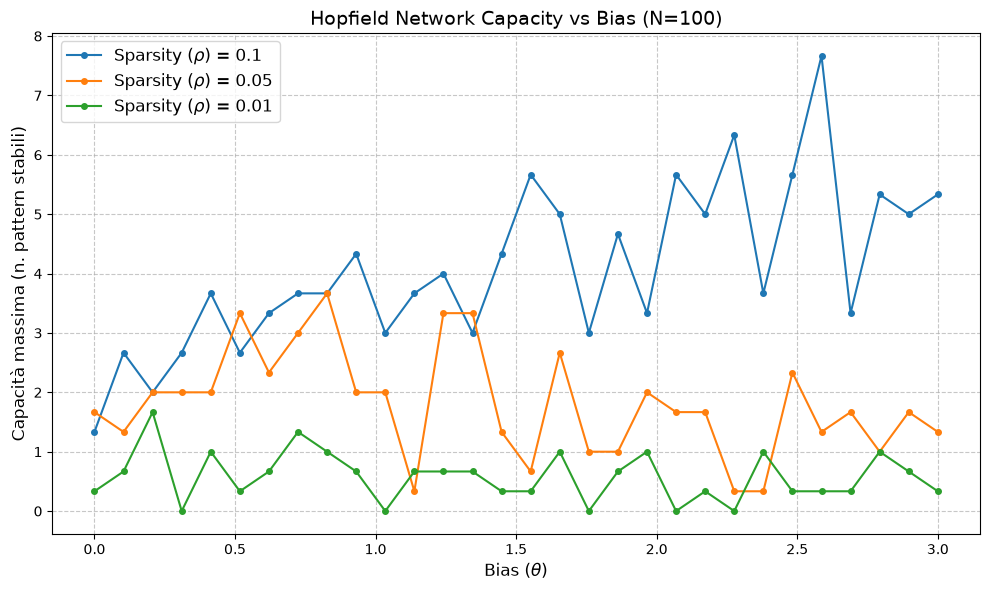

Rho = 0.1: Capacità massima ~7.7 pattern trovata con Theta ~= 2.59
Rho = 0.05: Capacità massima ~3.7 pattern trovata con Theta ~= 0.83
Rho = 0.01: Capacità massima ~1.7 pattern trovata con Theta ~= 0.21


In [78]:
import numpy as np
import matplotlib.pyplot as plt

class SparseHopfieldNetwork:
    def __init__(self, n_neurons, rho, theta):
        self.n_neurons = n_neurons
        self.rho = rho
        self.theta = theta
        self.W = np.zeros((n_neurons, n_neurons))

    def train(self, patterns):
        """
        Calcola i pesi usando la regola adattata per pattern sbilanciati, 
        mantenendo i pesi mediamente a zero[cite: 6, 7].
        """
        self.W = np.zeros((self.n_neurons, self.n_neurons))
        for p in patterns:
            # w_ij = (x_i - rho)(x_j - rho)
            centered_p = p - self.rho
            self.W += np.outer(centered_p, centered_p)
            
        # Rimuoviamo le auto-connessioni per favorire la capacità di memorizzazione
        np.fill_diagonal(self.W, 0)

    def is_stable(self, pattern):
        """
        Verifica la stabilità in un singolo step usando la regola di aggiornamento
        con il bias theta per pattern binari (0,1)[cite: 6, 7].
        """
        activation = self.W @ pattern
        # Applichiamo 0.5 + 0.5 * sign(attivazione - theta)
        # np.where è equivalente ed evita problemi con lo zero esatto
        new_state = np.where(activation - self.theta >= 0, 1, 0)
        return np.array_equal(new_state, pattern)


def generate_sparse_patterns(num_patterns, n_neurons, rho):
    """Genera pattern binari dove 1 appare con probabilità rho[cite: 7]."""
    return np.random.choice([0, 1], size=(num_patterns, n_neurons), p=[1-rho, rho])


def evaluate_capacity(n_neurons, rho, theta, max_patterns=100):
    """
    Trova il numero massimo di pattern che la rete riesce a mantenere 
    completamente stabili (capacità).
    """
    capacity = 0
    # Iteriamo per trovare il punto di rottura
    for p_count in range(1, max_patterns + 1):
        patterns = generate_sparse_patterns(p_count, n_neurons, rho)
        
        net = SparseHopfieldNetwork(n_neurons, rho, theta)
        net.train(patterns)
        
        # Controlliamo se TUTTI i pattern appresi sono stabili
        all_stable = all(net.is_stable(p) for p in patterns)
        
        if all_stable:
            capacity = p_count
        else:
            # Appena la rete fallisce su un set, ci fermiamo
            break
            
    return capacity


# --- SETUP DELL'ESPERIMENTO ---
N = 100 # Numero di neuroni (mantieni 100 per esecuzione rapida, alza a 200 per curve più precise)
rho_values = [0.10, 0.05, 0.01] # Attività da testare: 10%, 5%, 1%[cite: 7]
# Range del bias (theta). I valori efficaci dipendono dalla scala dell'attivazione, 
# che scala con rho. Testiamo un range generico.
theta_values = np.linspace(0, 3, 30) 

results = {rho: [] for rho in rho_values}

print("Inizio test (potrebbe richiedere qualche secondo)...")
for rho in rho_values:
    print(f"Test per rho = {rho}...")
    for theta in theta_values:
        # Per avere risultati più stabili, calcoliamo la media su 3 run per ogni theta
        avg_capacity = np.mean([evaluate_capacity(N, rho, theta, max_patterns=150) for _ in range(3)])
        results[rho].append(avg_capacity)

# --- PLOTTING ---
plt.figure(figsize=(10, 6))

for rho in rho_values:
    plt.plot(theta_values, results[rho], marker='o', markersize=4, label=f"Sparsity ($\\rho$) = {rho}")

plt.title(f"Hopfield Network Capacity vs Bias (N={N})", fontsize=14)
plt.xlabel("Bias ($\\theta$)", fontsize=12)
plt.ylabel("Capacità massima (n. pattern stabili)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

# Stampa del setup ottimale trovato
for rho in rho_values:
    max_cap = max(results[rho])
    best_theta = theta_values[np.argmax(results[rho])]
    print(f"Rho = {rho}: Capacità massima ~{max_cap:.1f} pattern trovata con Theta ~= {best_theta:.2f}")